In [1]:
import h5py
import pandas as pd
# import emcee
# import corner
import matplotlib.pyplot as plt
import numpy as np
import scienceplots
plt.style.use(['science', 'no-latex'])

from pybaselines import Baseline, utils
from datetime import datetime, timezone
# from scipy.optimize import curve_fit
# from scipy.signal import savgol_filter
# from scipy.ndimage import binary_dilation
from scipy.signal import find_peaks

from astropy.stats import median_absolute_deviation as MAD
# from astropy.modeling import models, fitting
# from astropy.convolution import convolve_models

from MPG_HDF5_libs import *

In [2]:
# configuration for the plots
plt.style.use(['science', 'no-latex'])

plt.rcParams.update({
    "axes.labelsize": 14,  # Font size for axis labels
    "xtick.labelsize": 16,  # Font size for x-axis tick labels
    "ytick.labelsize": 16   # Font size for y-axis tick labels
})   

plt.rcParams['axes.unicode_minus'] = False


# Accessing the data

In [3]:
filename = ('/home/chavango/Master/DATA/SKAMPI_data/EDD_2023-04-18T18_40_20.581801UTC_NkSzr.hdf5')


# Let's porint the structure of the hdf5 file
def print_hdf5_structure(name, obj):
    indent = '  ' * name.count('/')
    if isinstance(obj, h5py.Group):
        print(f"{indent}Group: {name}")
    elif isinstance(obj, h5py.Dataset):
        print(f"{indent}Dataset: {name}, Shape: {obj.shape}, Dtype: {obj.dtype}")

with h5py.File(filename, "r") as f:

    f.visititems(print_hdf5_structure)

Dataset: history, Shape: (12,), Dtype: [('processingtime', 'S23'), ('software', 'S256'), ('version', 'S128'), ('comment', 'S256')]
Group: monitor
  Group: monitor/acu
    Dataset: monitor/acu/actual_timestamp, Shape: (14781,), Dtype: float64
    Group: monitor/acu/ambient_temp_correction_config
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_1, Shape: (14781,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_10, Shape: (14781,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_2, Shape: (14781,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_3, Shape: (14781,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_4, Shape: (14781,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_5a, Shape: (14781,), Dtype: float64
      

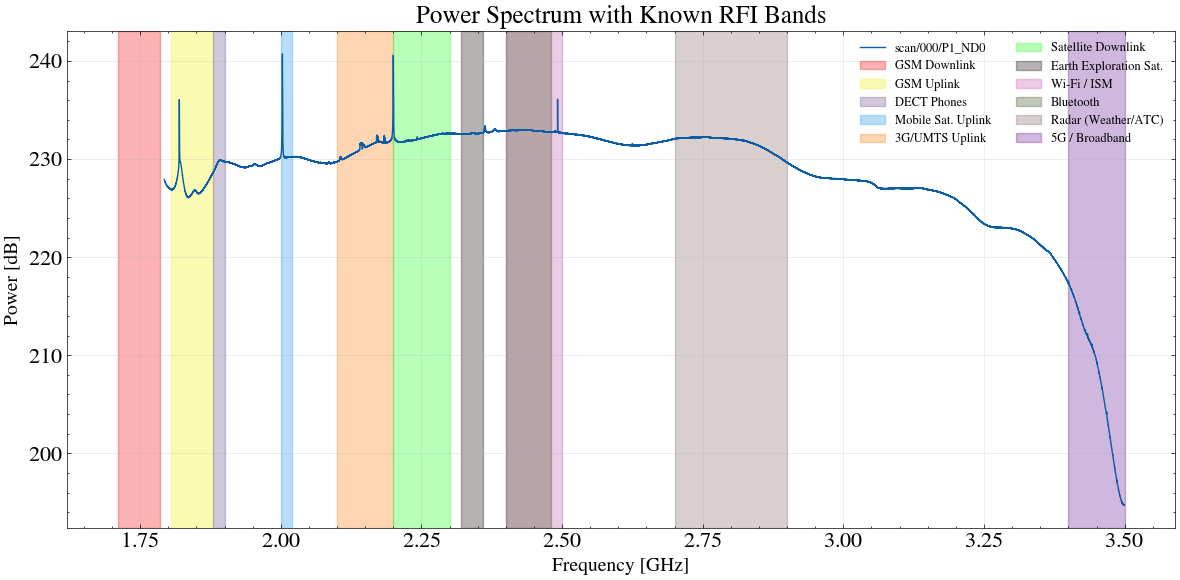

In [4]:

# Select different group os data

groups = [
    "scan/000/P1_ND0",
     #"scan/000/P1_ND1",
    # "scan/001/P0_ND0",
    # "scan/001/P0_ND1",
    # "scan/001/P1_ND0",
    # "scan/001/P1_ND1"
]


# Define RFI bands (GHz) for MeerKAT S-band (1.75–3.5 GHz)
rfi_bands = {
    "GSM Downlink": (1.71,  1.785),  # Global System for Mobile Communications
    "GSM Uplink": (1.805, 1.88),
    "DECT Phones": (1.88, 1.9),   # Digital Enhanced Cordless Telecommunications
    "Mobile Sat. Uplink": (2.00, 2.02),
    "3G/UMTS Uplink": (2.10, 2.20),   # Universal Mobile Telecommunications System
    "Satellite Downlink": (2.20, 2.30),
    "Earth Exploration Sat.": (2.32, 2.36),
    "Wi-Fi / ISM": (2.40, 2.50),   # Industrial, Scientific, and Medical band 
    "Bluetooth": (2.40, 2.48),
    "Radar (Weather/ATC)": (2.70, 2.90), #weather or Air traffic control-ATC
    "5G / Broadband": (3.40, 3.50)
}

colors = [
    "#F50000", "#f1f10694", "#67498361", "#1197f6f5","#ff7700ee","#16FF16DD",
    "#0C040234", "#c855a686", "#364d239c", "#8562625b", "#65118f60"
]

# Plot with RFI bands
with h5py.File(filename,'r') as f:
    for g in groups:
        spectrum = f[f"{g}/spectrum"][:,1600:-50]
        # Average convert the power spectrum to dB
        spectrum_dB = 10*np.log10(np.mean(spectrum**2, axis=0)) # in dB

        # define the varibles
        time = f['scan/000/P0_ND0/timestamp'][:,0]  # shape  (666,)
        freq = f[f"{g}/frequency"][1600:-50] / 1e9   # convert Hz -> GHz shape (65537,)
        ra = f[f"{g}/ra"][:]                        # deg
        dec = f[f"{g}/dec"][:]                      # deg

    
        # Plot
        plt.figure(figsize=(12,6))
        plt.plot(freq, spectrum_dB, label=g)

        # --- Overlay RFI bands ---
        for (label, (f_start, f_end)), color in zip(rfi_bands.items(), colors):
            plt.axvspan(f_start, f_end, color=color, alpha=0.3, label=label)

        # --- Labels and formatting ---
        plt.xlabel("Frequency [GHz]")
        plt.ylabel("Power [dB]")
        plt.title("Power Spectrum with Known RFI Bands", fontsize=18)
        plt.legend(loc="upper right", fontsize=9, ncol=2)
        plt.grid(alpha=0.3)
        plt.tight_layout()

        # plt.savefig(f"/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Plots/power_spectrum_with_RFI.png", dpi=300)
        # plt.savefig(f"/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Plots/power_spectrum_with_RFI.pdf", dpi=300)

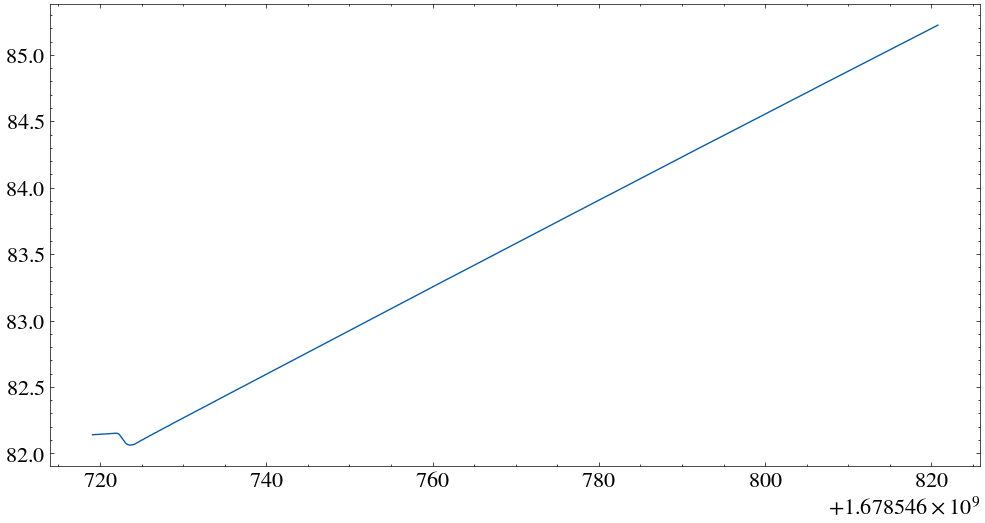

In [7]:
plt.figure(figsize=(12,6))
plt.plot(time, ra, label=g)

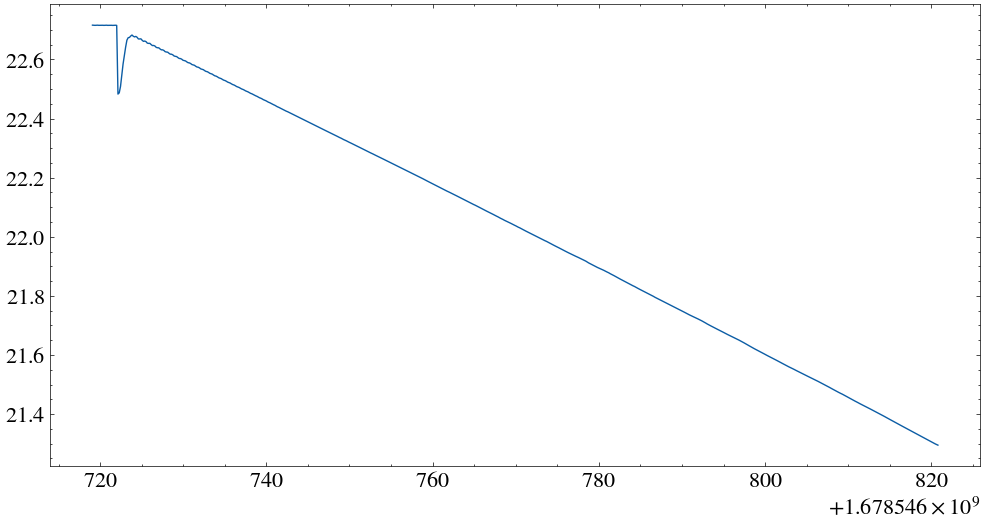

In [8]:
plt.figure(figsize=(12,6))
plt.plot(time, dec, label=g)

KeyError: 'Unable to synchronously open object (component not found)'

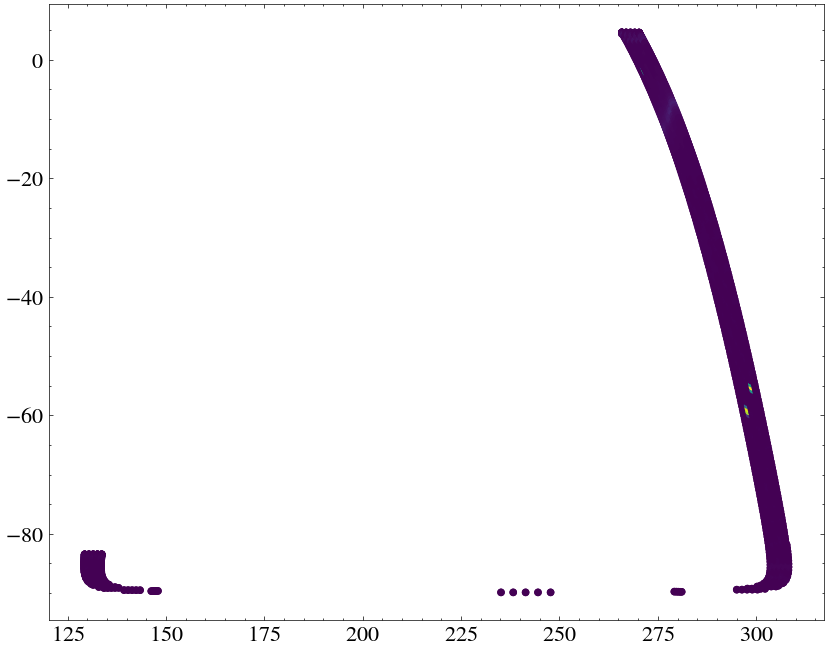

In [ ]:
groups1 = [
    "scan/000/P1_ND0",
    "scan/000/P1_ND1",
    "scan/001/P0_ND0",
    "scan/001/P0_ND1",
    "scan/001/P1_ND0",
    "scan/001/P1_ND1"
]

# Create one figure before the loop
plt.figure(figsize=(10, 8))

with h5py.File(filename, 'r') as f:
    for g in groups1:
        # --- Load data ---
        spectrum = f[f"{g}/spectrum"][:, 1600:-50]   # (time x freq)
        freq = f[f"{g}/frequency"][1600:-50] / 1e9   # GHz
        ra = f[f"{g}/ra"][:]                        # deg
        dec = f[f"{g}/dec"][:]                      # deg

        # --- Compute mean power per time sample ---
        mean_power = 10 * np.log10(np.mean(spectrum**2, axis=1))

        # --- Overlay scatter for this scan ---
        sc = plt.scatter(ra, dec, c=mean_power, cmap='viridis', s=20, label=g)

# --- After all scans are plotted ---
cbar = plt.colorbar(sc)
cbar.set_label("Mean Power [dB]")

plt.xlabel("Right Ascension [deg]")
plt.ylabel("Declination [deg]")
plt.title("Combined Sky Map of Mean Spectrum Intensity")
plt.grid(True, alpha=0.3)
plt.legend(loc='best', fontsize=8)
plt.show()


# How to apply the correlation to find if a certain RFI is appearing in all scans/antennas?


🎯 Goal

You have multiple scans (groups like scan/000/P1_ND0, etc.), each containing a spectrum (frequency × time or frequency × integration).
You want to know if a specific RFI (Radio Frequency Interference) feature appears consistently across all scans.

✅ Concept

If an RFI is persistent (e.g., a local transmitter, harmonic, or instrumental tone), it should produce a correlated spectral signature across multiple scans.

So we can measure the correlation between spectra from different scans to see if they share the same RFI pattern.

⚙️ Approach 1 – Correlation Across Frequency

If your spectrum is shaped like (time, freq), you can first average over time to get a mean spectrum per scan:

In [ ]:
mean_spectra = []

with h5py.File(filename, "r") as f:
    for g in groups1:
        spectrum = f[f"{g}/spectrum"][:, 1600:-50]   # shape (time, freq)

        mean_spec = np.mean(spectrum, axis=0)   # average over time
        mean_spectra.append(mean_spec)

# convert to array: (n_scans, n_freq)
mean_spectra = np.array(mean_spectra)

KeyError: 'Unable to synchronously open object (component not found)'

Compute Correlation Matrix

Now, compute the pairwise correlation between all scans:

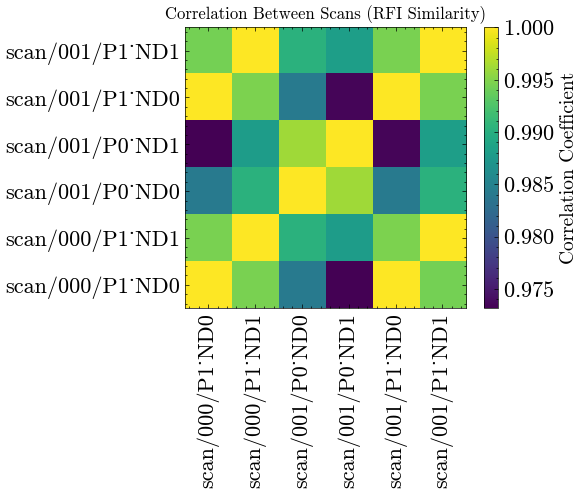

In [ ]:
corr_matrix = np.corrcoef(mean_spectra)

plt.figure(figsize=(6, 5))
plt.imshow(corr_matrix, cmap="viridis", origin="lower")
plt.colorbar(label="Correlation Coefficient")
plt.xticks(range(len(groups1)), groups1, rotation=90)
plt.yticks(range(len(groups1)), groups1)
plt.title("Correlation Between Scans (RFI Similarity)")
plt.tight_layout()
plt.show()


# Approach 2 – Detect Specific RFI Frequency Peaks

If you already know or suspect a certain RFI frequency (e.g., around 1420.4 MHz), you can check its presence in all scans:

In [ ]:
# Baseline correction

def base_correction(freq,power):
    """ 
    The function perform the baseline correction using the method: "Asymmetric Least Squar"

    Takes as entries:
    --------
    freq: array
    power: array

    Returns:
    ------
    The signal with the baseline corrected
    
    """

    # Step 1: define the baseli fitting
    baseline_fitter = Baseline(x_data=freq)
    bkg, params = baseline_fitter.asls(power, lam=1e7, p=0.02)

    # Step 2: Substract the baseline
    correct_baseline = power - bkg

    return correct_baseline

Detected peak frequencies (GHz): ['1.8197', '2.0029', '2.2001', '2.4920']


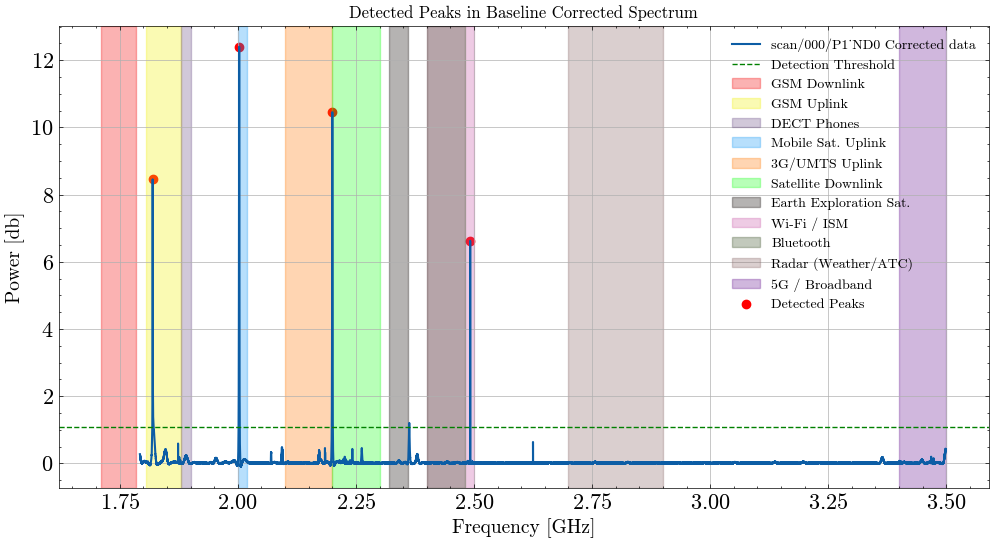

In [ ]:


# Base line corrected and peaks detection
for g in groups:

    power_base_core = base_correction(freq, spectrum_dB)

        
    peaks, propreties = find_peaks(power_base_core, 
                                height=MAD(power_base_core) + 3*np.std(power_base_core), 
                                distance=10,
                                prominence=1.5
                                )


    plt.figure(figsize=(12, 6))
    plt.plot(freq, power_base_core, label=f'{g} Corrected data', lw=1.5)
    # --- Overlay RFI bands ---
    for (label, (f_start, f_end)), color in zip(rfi_bands.items(), colors):
        plt.axvspan(f_start, f_end, color=color, alpha=0.3, label=label)

    plt.scatter(freq[peaks], power_base_core[peaks], color='red', label='Detected Peaks')
    plt.axhline(y=MAD(power_base_core) + 3*np.std(power_base_core), color='green', linestyle='--', label='Detection Threshold')
    plt.xlabel("Frequency [GHz]")
    plt.ylabel("Power [db]")
    plt.title("Detected Peaks in Baseline Corrected Spectrum")
    plt.grid()
    plt.legend()

    formatted_freqs = [f"{f:.4f}" for f in freq[peaks]]
    print(f"Detected peak frequencies (GHz): {formatted_freqs}")

plt.savefig(f"/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Plots/Detected_Peaks.png", dpi=300)
plt.savefig(f"/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Plots/Detected_Peaks.pdf", dpi=300)



In [ ]:
rfi_freq = freq[peaks]  # MHz or GHz depending on your units
tolerance = 0.002  # MHz window around the RFI


for rfi in rfi_freq:
        
    with h5py.File(filename, "r") as f:
        freq = f[f"{groups1[0]}/frequency"][1600:-50] / 1e6  # MHz
        idx = np.where((freq > rfi - tolerance) & (freq < rfi + tolerance))[0]
        

        # print each RFI frequency analysis
        print(f"\nRFI Frequency: {rfi:.4f} GHz")
        for g in groups1:
            spectrum = f[f"{g}/spectrum"][:,1600:-50]
            mean_spec = np.mean(spectrum, axis=0)
            rfi_power = np.mean([idx])
            print(f"{g}: RFI mean power = {rfi_power:.3f}")







RFI Frequency: 1.8197 GHz
scan/000/P1_ND0: RFI mean power = nan


/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.9/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.9/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


scan/000/P1_ND1: RFI mean power = nan
scan/001/P0_ND0: RFI mean power = nan
scan/001/P0_ND1: RFI mean power = nan
scan/001/P1_ND0: RFI mean power = nan
scan/001/P1_ND1: RFI mean power = nan

RFI Frequency: 2.0029 GHz
scan/000/P1_ND0: RFI mean power = nan
scan/000/P1_ND1: RFI mean power = nan
scan/001/P0_ND0: RFI mean power = nan
scan/001/P0_ND1: RFI mean power = nan
scan/001/P1_ND0: RFI mean power = nan
scan/001/P1_ND1: RFI mean power = nan

RFI Frequency: 2.2001 GHz
scan/000/P1_ND0: RFI mean power = nan
scan/000/P1_ND1: RFI mean power = nan
scan/001/P0_ND0: RFI mean power = nan
scan/001/P0_ND1: RFI mean power = nan
scan/001/P1_ND0: RFI mean power = nan
scan/001/P1_ND1: RFI mean power = nan

RFI Frequency: 2.4920 GHz
scan/000/P1_ND0: RFI mean power = nan
scan/000/P1_ND1: RFI mean power = nan
scan/001/P0_ND0: RFI mean power = nan
scan/001/P0_ND1: RFI mean power = nan
scan/001/P1_ND0: RFI mean power = nan
scan/001/P1_ND1: RFI mean power = nan


scan/000/P1_ND0
scan/001/P1_ND0

Just correlate the scan/000/p1 with scan/001/p1
because for the scan/000/p0 we do not have the second 

# Read all the SKAMPI DATA


In [ ]:
import glob
import os

# --- Define directory containing HDF5 files ---
data_path = '/home/chavango/Master/DATA/SKAMPI_data/*.hdf5'

# --- Collect all files matching pattern ---
hdf5_files = sorted(glob.glob(data_path))

print(f"Found {len(hdf5_files)} HDF5 files:")
for fpath in hdf5_files:
    print("  •", os.path.basename(fpath))
print("-" * 60)

# --- Function to print the internal structure of each HDF5 file ---
def print_hdf5_structure(name, obj):
    indent = '  ' * name.count('/')
    if isinstance(obj, h5py.Group):
        print(f"{indent} Group: {name}")
    elif isinstance(obj, h5py.Dataset):
        print(f"{indent} Dataset: {name}, Shape: {obj.shape}, Dtype: {obj.dtype}")

# --- Loop through each file and display structure ---
for fpath in hdf5_files:
    print(f"\n=== Exploring file: {os.path.basename(fpath)} ===")
    with h5py.File(fpath, "r") as f:
        f.visititems(print_hdf5_structure)


Found 6 HDF5 files:
  • EDD_2023-03-11T14_58_01.567317UTC_ErQFG.hdf5
  • EDD_2023-04-18T18_40_20.581801UTC_NkSzr.hdf5
  • EDD_2023-07-14T07_22_49.024178UTC_neSzZ.hdf5
  • EDD_2023-07-22T16_58_22.326155UTC_auMzw.hdf5
  • EDD_2023-08-07T15_07_54.890197UTC_tnEks.hdf5
  • EDD_2023-08-09T19_46_45.289915UTC_viGdg.hdf5
------------------------------------------------------------

=== Exploring file: EDD_2023-03-11T14_58_01.567317UTC_ErQFG.hdf5 ===
 Dataset: history, Shape: (9,), Dtype: [('processingtime', 'S23'), ('software', 'S256'), ('version', 'S128'), ('comment', 'S256')]
 Group: monitor
   Group: monitor/acu
     Dataset: monitor/acu/actual_timestamp, Shape: (2650,), Dtype: float64
     Group: monitor/acu/ambient_temp_correction_config
       Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_1, Shape: (2650,), Dtype: float64
       Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_10, Shape: (2650,), Dtype: float64
       Dataset: monitor

In [ ]:

# --- Define the scan groups you want to explore ---
groups = [
    "scan/000/P1_ND0",
    # "scan/000/P1_ND1",
    # "scan/001/P0_ND0",
    # "scan/001/P0_ND1",
    # "scan/001/P1_ND0",
    # "scan/001/P1_ND1"
]

# --- Loop through each file ---
for fpath in hdf5_files:
    print(f"\n=== File: {os.path.basename(fpath)} ===")

    with h5py.File(fpath, "r") as f:
        for g in groups:
            try:
                # --- Access datasets ---
                freq = f[f"{g}/frequency"][1600:-60] / 1e9     # convert to GHz
                spectrum = f[f"{g}/spectrum"][:,1600:-60]        # (time × freq)
                time = f[f"{g}/timestamp"][:]           # time samples

                # --- Print summaries ---
                print(f"\n→ Group: {g}")
                print(f"  Frequency shape: {freq.shape} | Range: {freq.min():.3f}-{freq.max():.3f} GHz")
                print(f"  Spectrum shape:  {spectrum.shape}")
                print(f"  Time samples:    {len(time)}")

            except KeyError:
                print(f"  [!] Missing data for {g}")



=== File: EDD_2023-03-11T14_58_01.567317UTC_ErQFG.hdf5 ===

→ Group: scan/000/P1_ND0
  Frequency shape: (63877,) | Range: 1.793-3.498 GHz
  Spectrum shape:  (664, 63877)
  Time samples:    664

=== File: EDD_2023-04-18T18_40_20.581801UTC_NkSzr.hdf5 ===

→ Group: scan/000/P1_ND0
  Frequency shape: (63877,) | Range: 1.793-3.498 GHz
  Spectrum shape:  (668, 63877)
  Time samples:    668

=== File: EDD_2023-07-14T07_22_49.024178UTC_neSzZ.hdf5 ===

→ Group: scan/000/P1_ND0
  Frequency shape: (63877,) | Range: 1.793-3.498 GHz
  Spectrum shape:  (663, 63877)
  Time samples:    663

=== File: EDD_2023-07-22T16_58_22.326155UTC_auMzw.hdf5 ===

→ Group: scan/000/P1_ND0
  Frequency shape: (63877,) | Range: 1.793-3.498 GHz
  Spectrum shape:  (1960, 63877)
  Time samples:    1960

=== File: EDD_2023-08-07T15_07_54.890197UTC_tnEks.hdf5 ===

→ Group: scan/000/P1_ND0
  Frequency shape: (63877,) | Range: 1.793-3.498 GHz
  Spectrum shape:  (664, 63877)
  Time samples:    664

=== File: EDD_2023-08-09T19

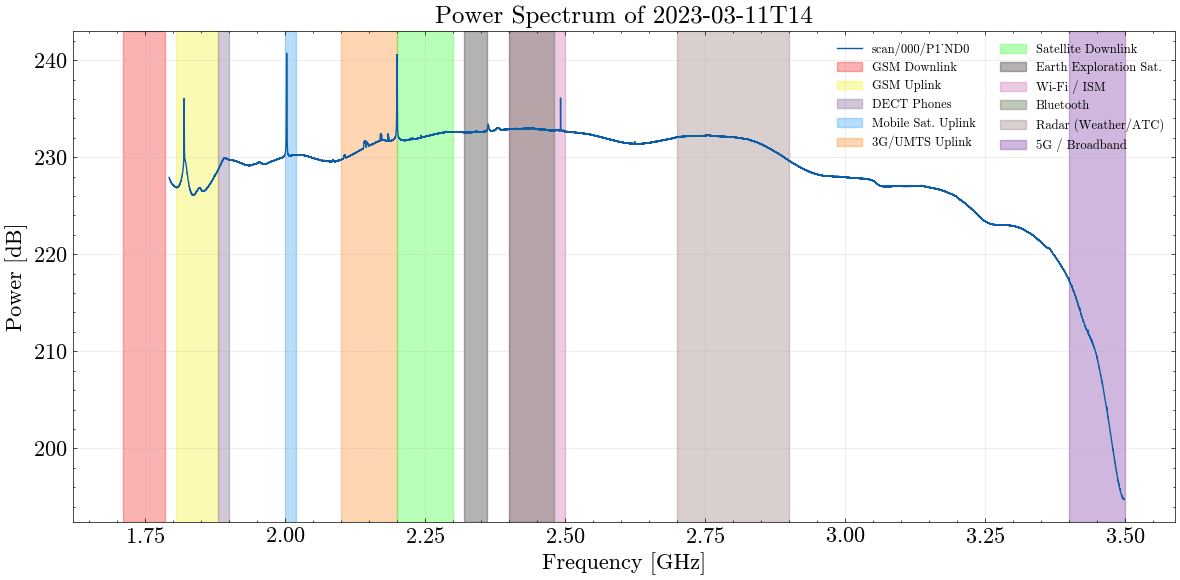

In [ ]:
# --- Loop through each file ---
for fpath in hdf5_files:
    base = os.path.basename(fpath)
    name = base.replace(".hdf5", "")
    date_code = name.split("_")[1]


    with h5py.File(fpath, "r") as f:
        for g in groups:
               
            spectrum = f[f"{g}/spectrum"][:,1600:-60]        # (time × freq)
            freq = f[f"{g}/frequency"][1600:-60] / 1e9   # GHz
            # Average over time axis
            spectrum_dB = 10*np.log10(np.mean(spectrum**2, axis=0)) # in dB

            # Plota
            plt.figure(figsize=(12,6))
            plt.plot(freq, spectrum_dB, label=g)

            # --- Overlay RFI bands ---
            for (label, (f_start, f_end)), color in zip(rfi_bands.items(), colors):
                plt.axvspan(f_start, f_end, color=color, alpha=0.3, label=label)                   



            # --- Labels and formatting ---
            plt.xlabel("Frequency [GHz]", fontsize=16)
            plt.ylabel("Power [dB]", fontsize=16)
            plt.title(f"Power Spectrum of {date_code}", fontsize=18)
            plt.legend(loc="upper right", fontsize=9, ncol=2)
            plt.grid(alpha=0.3)
            plt.tight_layout()

            #plt.savefig(f"/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Plots/{date_code}_power_spectrum_with_RFI.png", dpi=300)
            #plt.savefig(f"/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Plots/{date_code}_power_spectrum_with_RFI.pdf", dpi=300)

        break

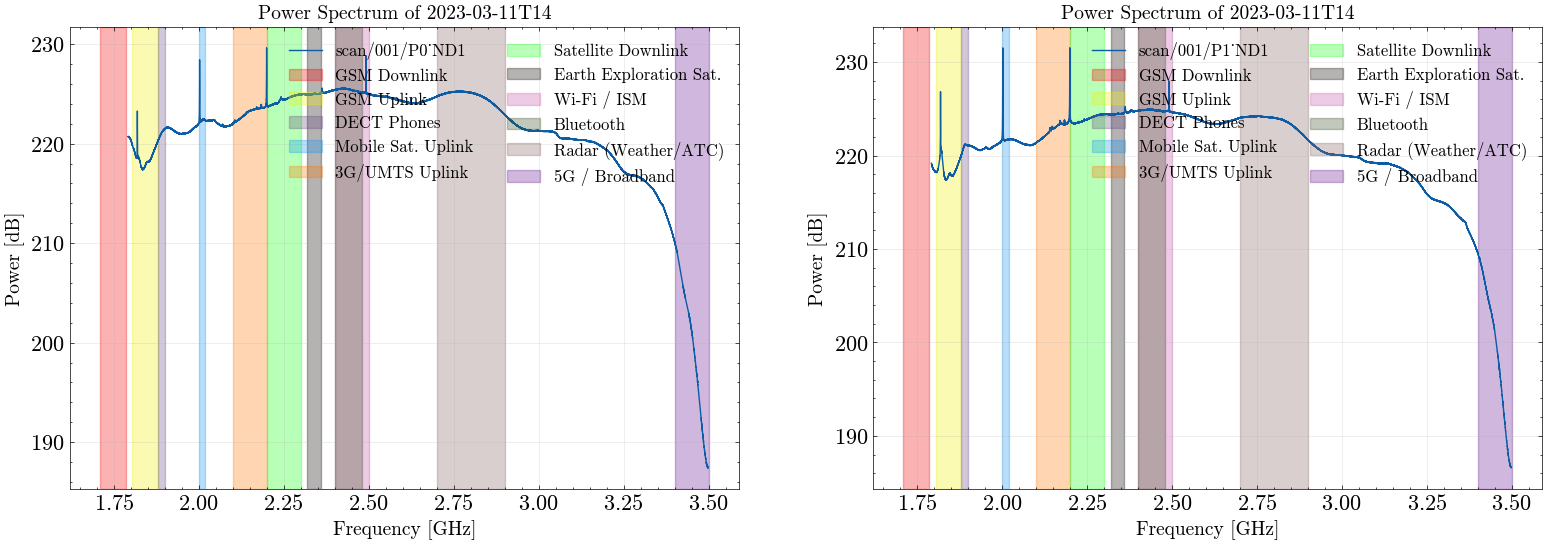

In [ ]:
group = [
    "scan/001/P0_ND0",
    "scan/001/P0_ND1",
]
group1 = [
    "scan/001/P1_ND0",
    "scan/001/P1_ND1"
]
# --- Loop through each file ---
for fpath in hdf5_files:
    base = os.path.basename(fpath)
    name = base.replace(".hdf5", "")
    date_code = name.split("_")[1]


    with h5py.File(fpath, "r") as f:

        fig, ax = plt.subplots(1,2, figsize=(19,6))
        try:
            for g in group:

                # --- Access datasets ---
                freq = f[f"{g}/frequency"][1600:-60] / 1e9     # convert to GHz
                spectrum = f[f"{g}/spectrum"][:,1600:-60]        # (time × freq)
                time = f[f"{g}/timestamp"][:]           # time samples

                                # Average over time axis
                spectrum_dB = 10*np.log10(np.mean(spectrum**2, axis=0)) # in dB

            # --- Overlay RFI bands ---
            for (label, (f_start, f_end)), color in zip(rfi_bands.items(), colors):
                ax[0].axvspan(f_start, f_end, color=color, alpha=0.3, label=label)                   

            

            ax[0].plot(freq, spectrum_dB, label=g)
            ax[0].set_xlabel("Frequency [GHz]")
            ax[0].set_ylabel("Power [dB]")
            ax[0].set_title(f"Power Spectrum of {date_code}", fontsize=14)
            ax[0].legend(loc="upper right", fontsize=12, ncol=2)
            ax[0].grid(alpha=0.3)

            for g in group1:
                            # --- Access datasets ---
                freq = f[f"{g}/frequency"][1600:-60] / 1e9     # convert to GHz
                spectrum = f[f"{g}/spectrum"][:,1600:-60]        # (time × freq)
                time = f[f"{g}/timestamp"][:]           # time samples

                    # Average over time axis
                spectrum_dB = 10*np.log10(np.mean(spectrum**2, axis=0)) # in dB

            # --- Overlay RFI bands ---
            for (label, (f_start, f_end)), color in zip(rfi_bands.items(), colors):
                ax[1].axvspan(f_start, f_end, color=color, alpha=0.3, label=label) 

            ax[1].plot(freq, spectrum_dB, label=g)
            ax[1].set_xlabel("Frequency [GHz]")
            ax[1].set_ylabel("Power [dB]")
            ax[1].set_title(f"Power Spectrum of {date_code}", fontsize=14)
            ax[1].legend(loc="upper right", fontsize=12, ncol=2)
            ax[1].grid(alpha=0.3)

        except KeyError:
            print(f"  [!] Missing data on {g} for {date_code} ")


        break


  [!] Missing Spectrum for scan/001/P0_ND0
  [!] Missing Spectrum for scan/001/P0_ND1
  [!] Missing Spectrum for scan/001/P1_ND0
  [!] Missing Spectrum for scan/001/P1_ND1


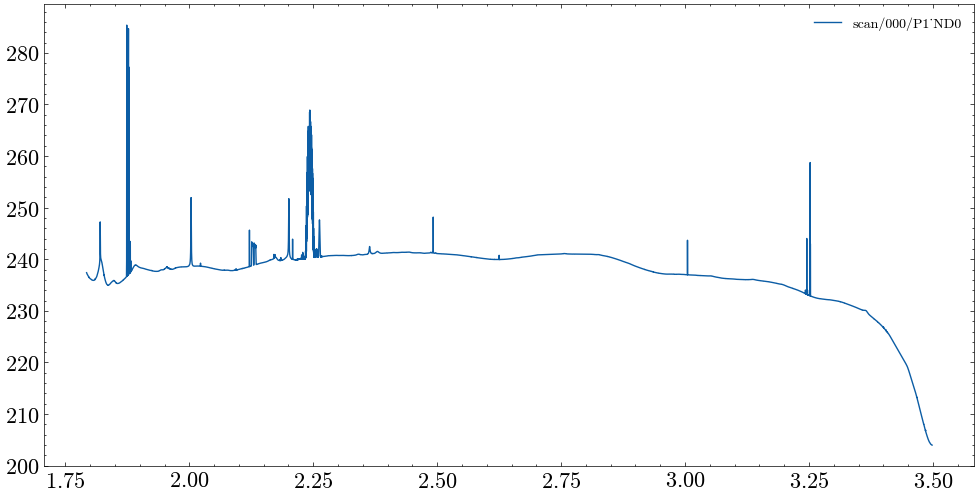

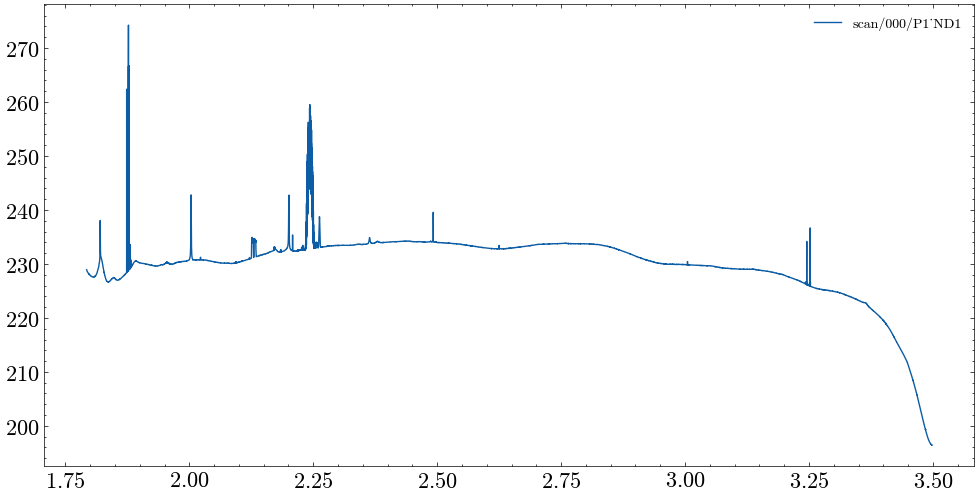

In [ ]:
data =  ('/home/chavango/Master/DATA/SKAMPI_data/EDD_2023-07-22T16_58_22.326155UTC_auMzw.hdf5')

groups1 = [
    "scan/000/P1_ND0",
    "scan/000/P1_ND1",
    "scan/001/P0_ND0",
    "scan/001/P0_ND1",
    "scan/001/P1_ND0",
    "scan/001/P1_ND1",
]



with h5py.File(data, "r") as f:
    for g in groups1:
        try:
                        
            spectrum = f[f"{g}/spectrum"][:,1600:-60]        # (time × freq)
            freq = f[f"{g}/frequency"][1600:-60] / 1e9   # GHz
            # Average over time axis
            spectrum_dB = 10*np.log10(np.mean(spectrum**2, axis=0)) # in dB

            # Plot
            plt.figure(figsize=(12,6))
            plt.plot(freq, spectrum_dB, label=g) 
            plt.legend() 

        except KeyError:
            print(f"  [!] Missing Spectrum for {g}")


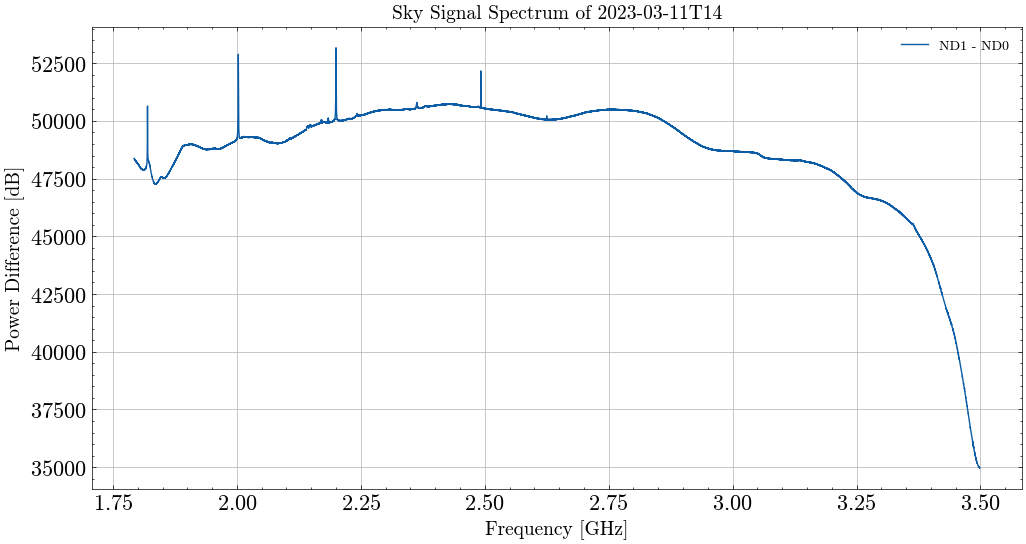

In [ ]:

# --- Loop through each file ---
for fpath in hdf5_files:
    base = os.path.basename(fpath)
    name = base.replace(".hdf5", "")
    date_code = name.split("_")[1]


    with h5py.File(fpath, "r") as f:
        try:
            for g in group:


                spectrum = f[f"{g}/spectrum"][:,1600:-60]        # (time × freq)

                # --- Access datasets ---
                freq = f[f"{g}/frequency"][1600:-60] / 1e9     # convert to GHz
                time = f[f"{g}/timestamp"][:]           # time samples

                                # Average over time axis
                spectrum_dB_ND0 = 10*np.log10(np.mean(spectrum**2, axis=0)) # in dB

            for g in group1:
                            # --- Access datasets ---
                freq = f[f"{g}/frequency"][1600:-60] / 1e9     # convert to GHz
                spectrum = f[f"{g}/spectrum"][:,1600:-60]        # (time × freq)
                time = f[f"{g}/timestamp"][:]           # time samples

                    # Average over time axis
                spectrum_dB_ND1 = 10*np.log10(np.mean(spectrum**2, axis=0)) # in dB

            # Calculate the difference between ND1 and ND0
            power_diff = spectrum_dB_ND1 * spectrum_dB_ND0

            # Plot the real signal from the sky
            plt.figure(figsize=(12,6))
            plt.plot(freq, power_diff, label='ND1 - ND0')
            plt.xlabel("Frequency [GHz]")
            plt.ylabel("Power Difference [dB]")
            plt.title(f"Sky Signal Spectrum of {date_code}", fontsize=14)
            plt.legend()
            plt.grid()

        except KeyError:
            print(f"  [!] Missing data on {g} for {date_code} ")

        break


# Shy Map of the observations

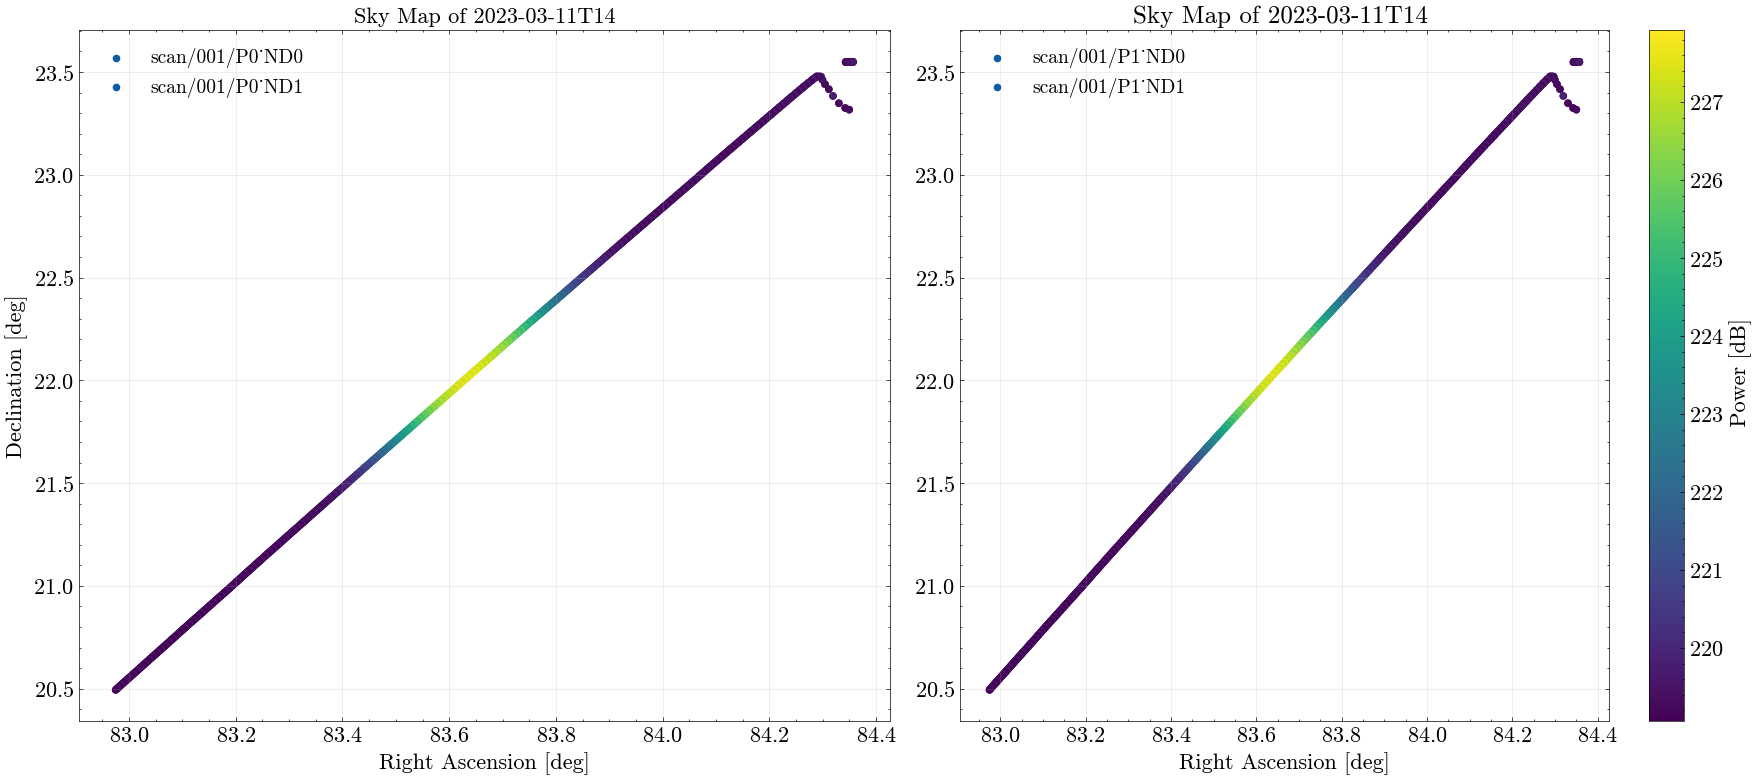

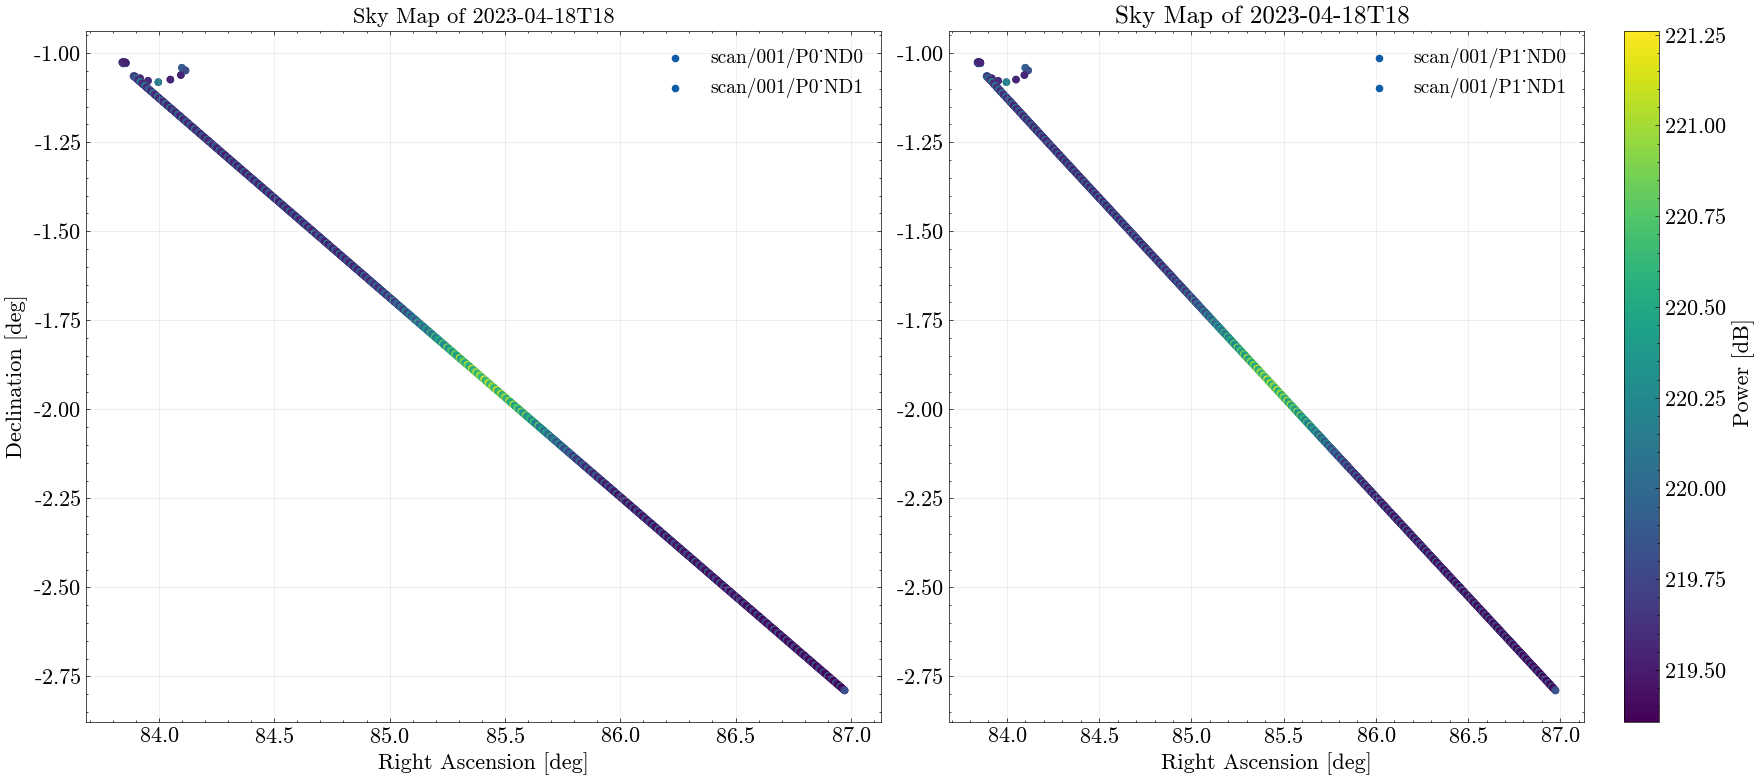

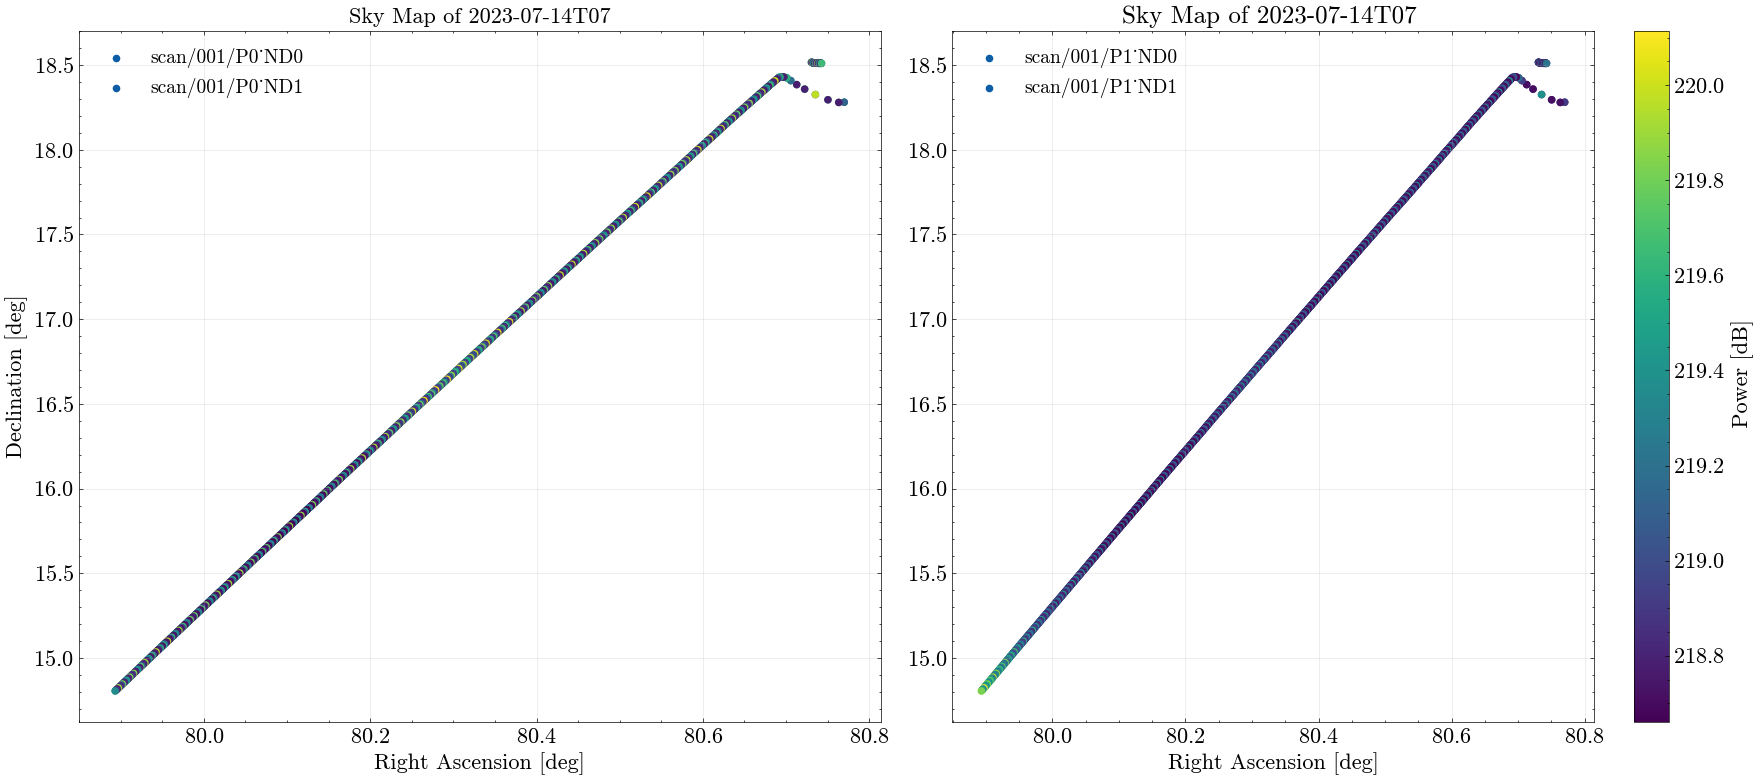

[!] Missing data in 'Unable to synchronously open object (component not found)' for 2023-07-22T16


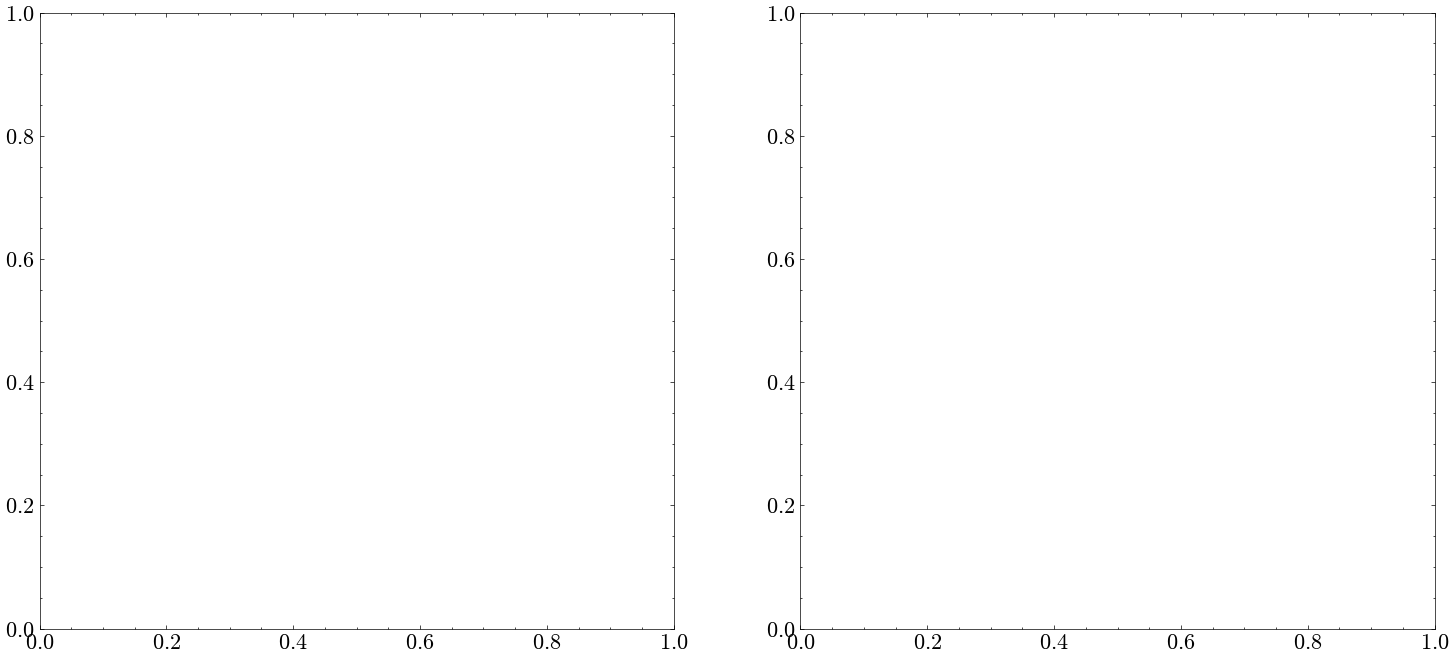

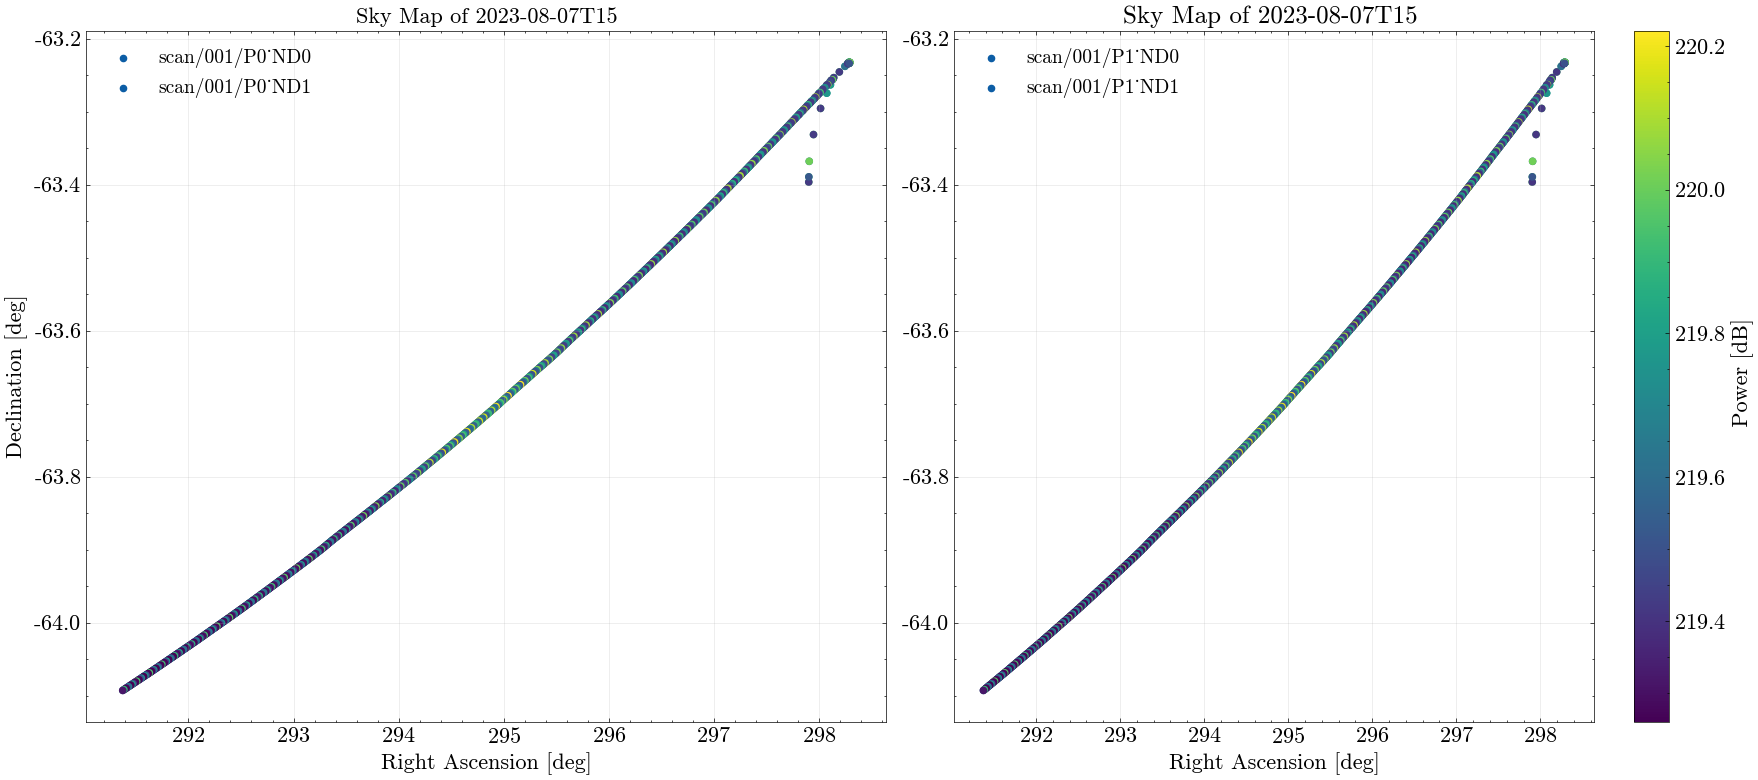

[!] Missing data in 'Unable to synchronously open object (component not found)' for 2023-08-09T19


SyntaxError: 'break' outside loop (2546796715.py, line 67)

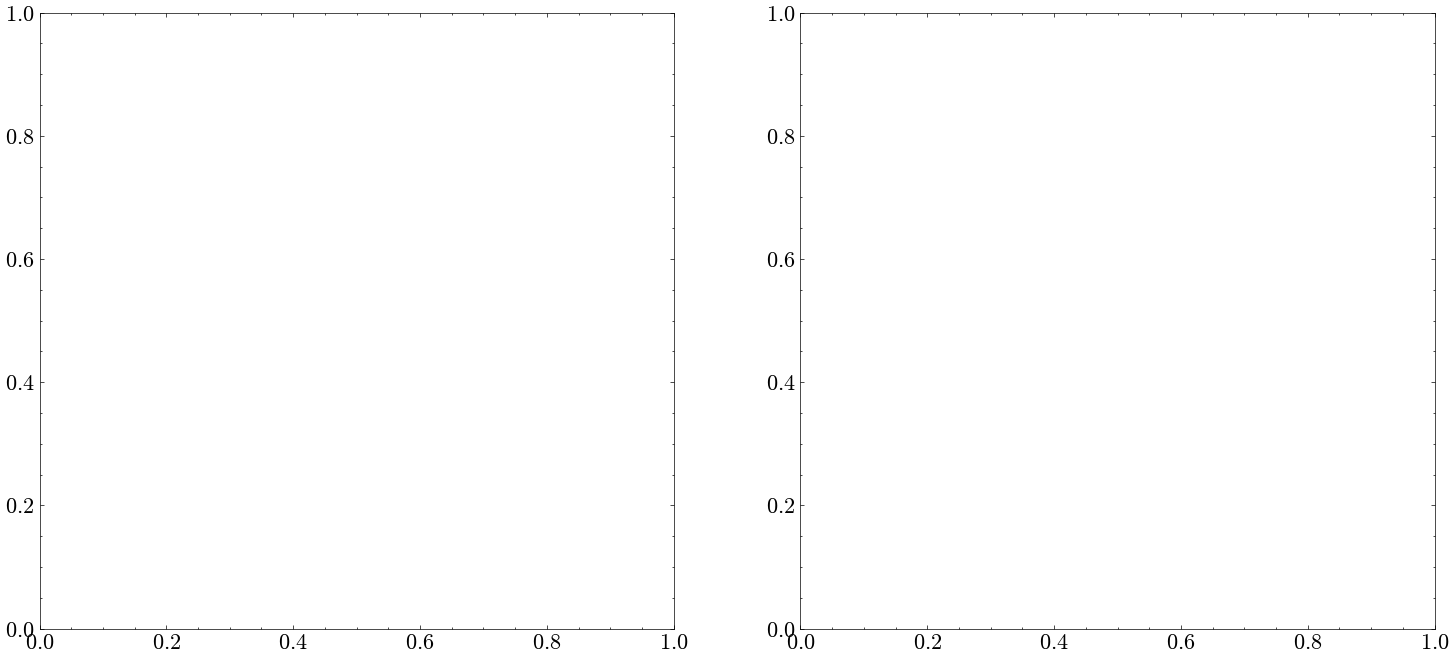

In [ ]:

for fpath in hdf5_files:
    base = os.path.basename(fpath)
    name = base.replace(".hdf5", "")
    date_code = name.split("_")[1]
    

    # --- Open the HDF5 file ---
    with h5py.File(fpath, "r") as f:
        try:
            # --- Create figure and axes ---
            fig, ax = plt.subplots(1, 2, figsize=(18, 8))

            # --- FIRST PANEL ---
            for g in group:
                # Load data
                spectrum = f[f"{g}/spectrum"][:, 1600:-50]   # (time x freq)
                freq = f[f"{g}/frequency"][1600:-50] / 1e9   # GHz
                ra = f[f"{g}/ra"][:]                        # deg
                dec = f[f"{g}/dec"][:]                      # deg

                # Compute mean power per time sample (in dB)
                spectrum_dB = 10 * np.log10(np.mean(spectrum**2, axis=1) + 1e-12)

                # Scatter plot
                sc = ax[0].scatter(ra, dec, c=spectrum_dB, cmap='viridis', s=20, label=g)

            # Add colorbar and labels (outside loop)
            #cbar0 = fig.colorbar(sc, ax=ax[0])
            #cbar0.set_label(" Power [dB]")
            ax[0].set_xlabel("Right Ascension [deg]",fontsize=16)
            ax[0].set_ylabel("Declination [deg]", fontsize=16)
            ax[0].set_title(f"Sky Map of {date_code}", fontsize=16)
            ax[0].grid(True, alpha=0.3)
            ax[0].legend(loc='best', fontsize=14)

            # --- SECOND PANEL ---
            for g in group1:
                # Load data
                spectrum = f[f"{g}/spectrum"][:, 1600:-50]   # (time x freq)
                freq = f[f"{g}/frequency"][1600:-50] / 1e9   # GHz
                ra = f[f"{g}/ra"][:]                        # deg
                dec = f[f"{g}/dec"][:]                      # deg

                # Compute mean power per time sample (in dB)
                spectrum_dB = 10 * np.log10(np.mean(spectrum**2, axis=1) + 1e-12)

                # Scatter plot
                sc = ax[1].scatter(ra, dec, c=spectrum_dB, cmap='viridis', s=20, label=g)

            # Add colorbar and labels (outside loop)
            cbar1 = fig.colorbar(sc, ax=ax[1])
            cbar1.set_label(" Power [dB]", fontsize=16)
            ax[1].set_xlabel("Right Ascension [deg]",fontsize=16)
            #ax[1].set_ylabel("Declination [deg]", fontsize=16)
            ax[1].set_title(f"Sky Map of {date_code} ", fontsize=18)
            ax[1].grid(True, alpha=0.3)
            ax[1].legend(loc='best', fontsize=14)

            # --- Final adjustments ---
            plt.tight_layout()
            plt.show()

        except KeyError as e:
            print(f"[!] Missing data in {e} for {date_code}")


break


# Water plot


[+] Processing file: EDD_2023-03-11T14_58_01.567317UTC_ErQFG


    Duration covered: 1.69 minutes


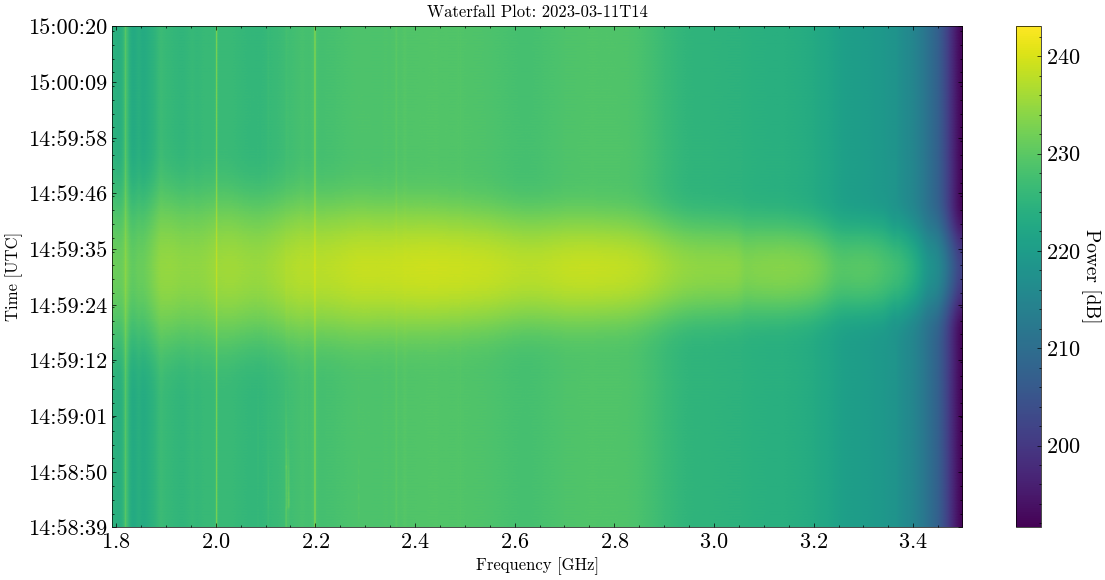


[+] Processing file: EDD_2023-04-18T18_40_20.581801UTC_NkSzr
    Duration covered: 1.71 minutes


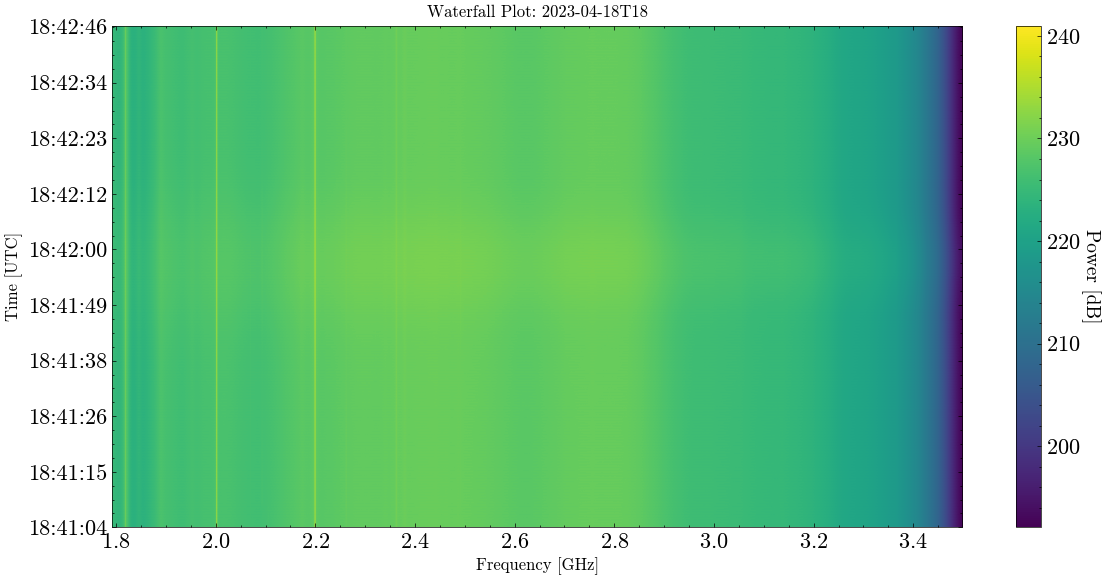


[+] Processing file: EDD_2023-07-14T07_22_49.024178UTC_neSzZ
    Duration covered: 1.69 minutes


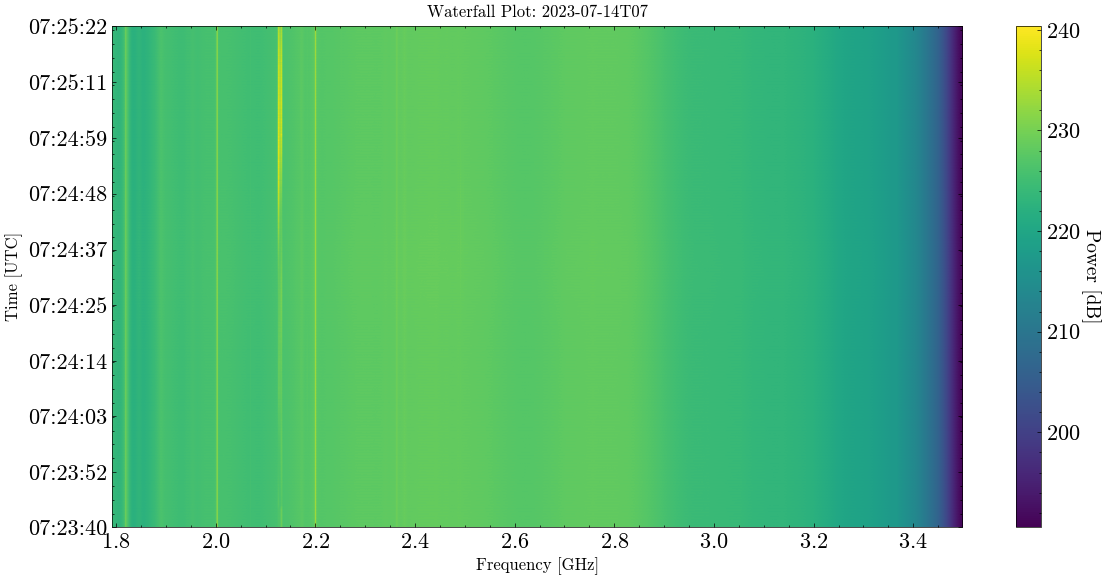


[+] Processing file: EDD_2023-07-22T16_58_22.326155UTC_auMzw
    Duration covered: 20.03 minutes


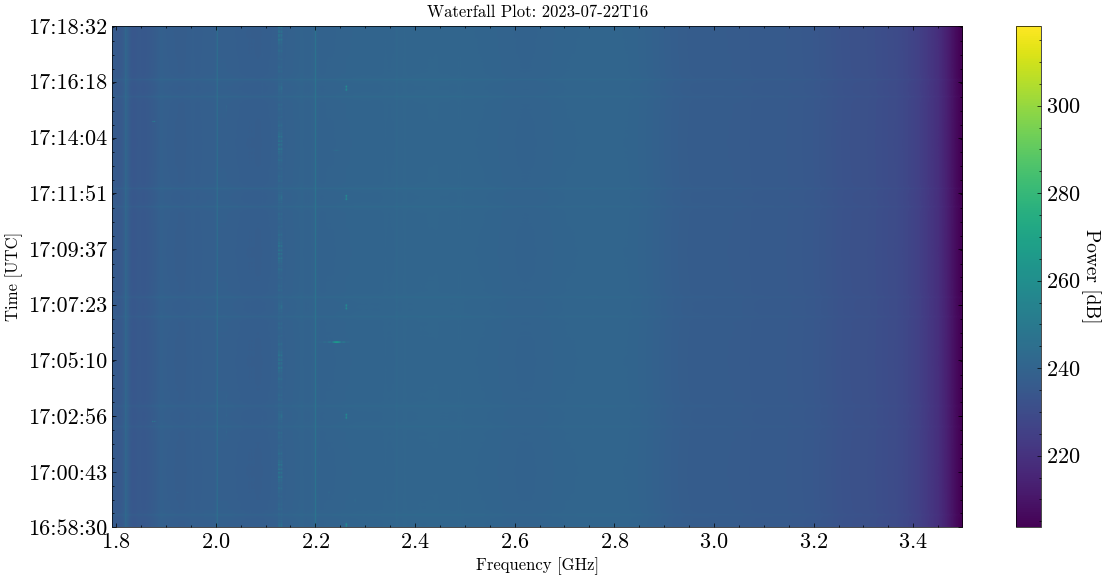


[+] Processing file: EDD_2023-08-07T15_07_54.890197UTC_tnEks
    Duration covered: 1.69 minutes


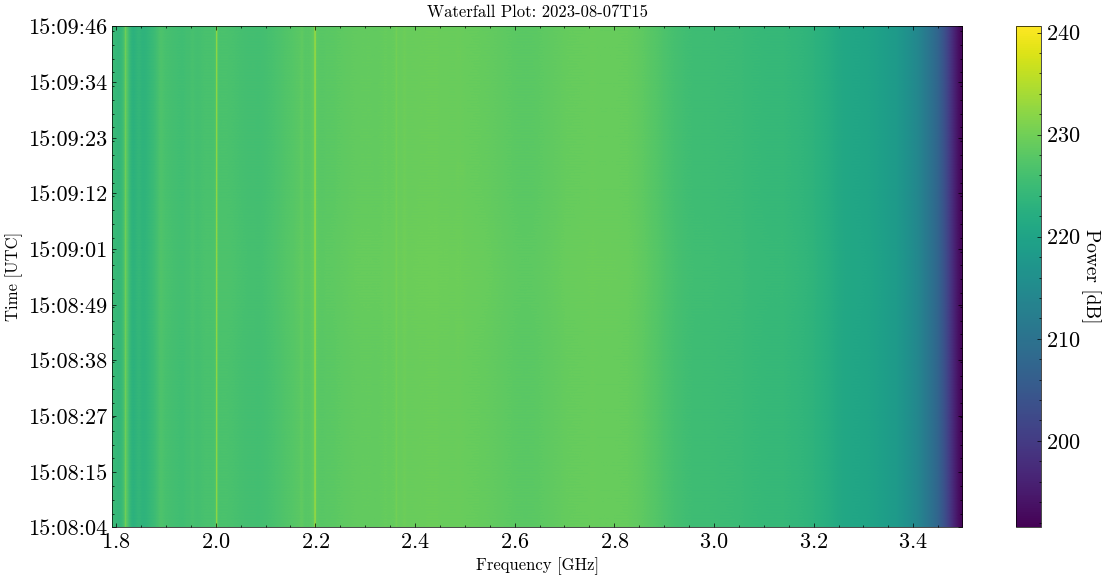


[+] Processing file: EDD_2023-08-09T19_46_45.289915UTC_viGdg
    Duration covered: 5.03 minutes


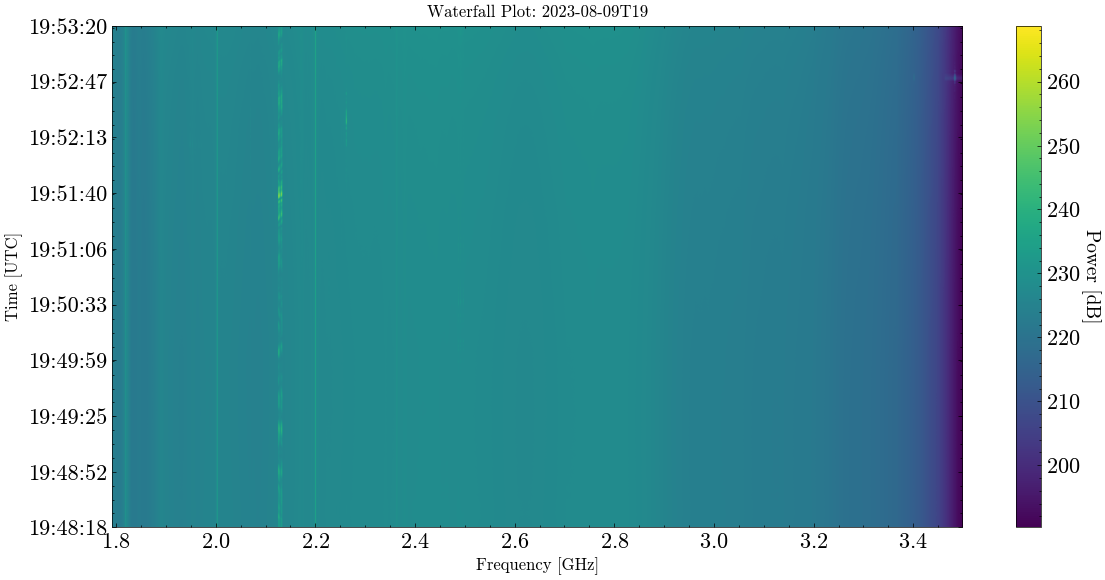

In [ ]:

# --- Loop through files ---
for fpath in hdf5_files:
    base = os.path.basename(fpath)
    name = base.replace(".hdf5", "")
    date_code = name.split("_")[1]

    print(f"\n[+] Processing file: {name}")

    with h5py.File(fpath, "r") as f:
        for g in groups:
            try:
                # --- Load data ---
                spectrum = f[f"{g}/spectrum"][:, 1600:-50]        # (time x freq)
                freq = f[f"{g}/frequency"][1600:-50] / 1e9        # GHz
                time = f[f"{g}/timestamp"][:, 0]                  # seconds (UTC)

                # --- Convert spectrum to dB ---
                spectrum_dB = 10 * np.log10(spectrum**2 + 1e-12)

                # --- Convert time to UTC datetime ---
                time_utc = pd.to_datetime(time, unit="s", utc=True)


                # --- Compute total duration covered ---
                duration_sec = (time_utc[-1] - time_utc[0]).total_seconds()
                duration_min = duration_sec / 60
                
                
                print(f"    Duration covered: {duration_min:.2f} minutes")


                # --- Plot waterfall ---
                fig, ax = plt.subplots(figsize=(12, 6))
                im = ax.imshow(
                    spectrum_dB,
                    aspect='auto',
                    extent=[freq.min(), freq.max(), 0, spectrum_dB.shape[0]],
                    origin='lower',
                    cmap='viridis'
                )

                # --- Axis labels and title ---
                ax.set_xlabel("Frequency [GHz]", fontsize=12)
                ax.set_ylabel("Time [UTC]", fontsize=12)
                ax.set_title(f"Waterfall Plot: {date_code}")

                # --- Colorbar ---
                cbar = plt.colorbar(im, ax=ax)
                cbar.set_label("Power [dB]", rotation=270, labelpad=15)

                # --- Y-axis ticks (Time in UTC) ---
                n_ticks = 10
                tick_positions = np.linspace(0, len(time_utc)-1, n_ticks, dtype=int)
                tick_labels = [time_utc[i].strftime("%H:%M:%S") for i in tick_positions]
                ax.set_yticks(tick_positions)
                ax.set_yticklabels(tick_labels)

                # --- Improve layout ---
                plt.tight_layout()
                plt.show()

            except KeyError:
                print(f"  [!] Missing data for group '{g}' in {date_code}")
            break
